# Rocket Model Analysis

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [2]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(root))

In [3]:
"""
ALL SYMBOLS, CONSTANTS AND FUNCTIONS
"""
# Variables
t = sp.Symbol("t")
# Adjustable parameters
k1, k2, T = sp.symbols("k1 k2 T")
# Constants
ka = 0.0655         # actuator's push gain
inv_tm = 1.0672     # engine bandwidth (1/tm = 1.0672)
c0 = 9.81           # gravitational coupling
mu = 1.20           # aerodynamic rigidity
ad = 0.35           # aerodynamic damping
kd = 8.5            # nozzle's effectivity
ke = 0.12           # coupling from missalignment
ts = 0.05           # servo's bandwidth (1/ts = 20)
lmd = 0.6           # IMO's speed-position ratio
# Inputs
u1 = sp.Function('u1')(t)
u2 = sp.Function('u2')(t)
inputs = [u1, u2]
# States
acc = sp.Function('a')(t)   # axial acceleration
theta = sp.Function('0')(t) # angular velocity
omega = sp.Function('w')(t) # momentum balacing
delta = sp.Function('d')(t) # nozzle's servo dynamic
states = [acc, theta, omega, delta]
# Outputs
y1 = sp.Function('y1')(t)
y2 = sp.Function('y2')(t)
outputs = [y1, y2]

"""
EQUATION SYSTEM DEFINITION
"""
# States equation system
dx1 = sp.Eq(acc.diff(t), -((1 + k1*ka)*inv_tm)*acc - c0*theta + ((k1*ka)*inv_tm)*u1)
dx2 = sp.Eq(theta.diff(t), omega)
dx3 = sp.Eq(omega.diff(t), mu*theta - ad*omega + kd*delta + ke*acc)
dx4 = sp.Eq(delta.diff(t), -(1/ts)*delta -(k2/ts)*theta - ((lmd*k2)/ts)*omega + (k2/ts)*u2)
state_system = [dx1, dx2, dx3, dx4]
# Output equation system
out1 = sp.Eq(y1, acc)
out2 = sp.Eq(y2, theta)
output_system = [out1, out2]

## (A) Modelado del Sistema

### 1) Análisis del Sistema
Las entradas son los valores que deseamos de aceleración axial y ángulo de cabeceo para nuestro cohete por lo que serán las variables por comparar para obtener nuestro error.
Los bloques A/D son convertidores de señales analógicas a digitales o ADC para que la computadora pueda interpretar los datos que recibe de los sensores.
Computadora, obtiene las entradas y la retroalimentación y las compara para obtener nuestro error el cual se multiplicará por las constantes K1 y K2 para la respectiva entrada, actualizará el motor y el servo con los resultados en un tiempo dado que será el tiempo de muestreo. 

- D/A: Convertidor digital a analógico para poder comunicarse con el motor y el
servo.
- Amplificadores: Para que la señal digital débil se amplifique e influya en el
comportamiento del motor y el servo.
- Dinámica del cohete, los valores de aceleración y de nuestras entradas
afectarán a la dinámica de nuestro cohete, afectando su aceleración axial y su
ángulo de cabeceo.
- k_a: Ganancia del actuador de empuje, constante de proporcionalidad que transforma
la señal de control en una aceleración axial física.
- 1/T_m: Ancho de banda del motor, inercia del motor como un retardo de primer orden
indica qué tan rápido puede cambiar el empuje físico ante un cambio de comando.
- c_theta: Acoplamiento gravitatorio, es la pérdida de aceleración axial por la inclinación del
cohete.
- μ: Rigidez aerodinámica (desestabilizante), es el momento de giro generado por el
viento sobre el cohete cuando el CP está sobre el CM.
- a_d: Amortiguamiento aerodinámico, es la resistencia del aire ante la rotación del
cohete.
- k_delta: Efectividad de la tobera, es la aceleración angular que se produce por radián de
deflexión de la tobera.
- k_epsilon: Acoplamiento por desalineación del empuje, al no pasar el vector del empuje por
el CM genera un torque parásito que perturba la aceleración angular.
- 1/T_S: Ancho de banda del servo, es la respuesta del servo ante un comando, es más
rápida su respuesta que la del motor.
- λ: Proporción velocidad / Posición de la IMU, pondera la señal de velocidad angular
en relación con el ángulo en la lectura, introduce un amortiguamiento artificial (como
un control PD).
- K1: Ganancia del canal de empuje, modula la retroalimentación de la aceleración
axial, el polo efectivo se desplaza a la izquierda más rápido acelerando la respuesta
del empuje y reduciendo el error en régimen permanente.
El error en régimen permanente (también llamado error en estado estacionario) es la diferencia que queda entre el valor de la señal de referencia (lo que queremos que haga el sistema) y el valor real de la salida cuando el tiempo pasa y el sistema ya se ha
estabilizado.
- K2: Ganancia del canal de dirección, determina la intensidad con la que se mueve la
tobera para corregir la actitud del cohete, busca estabilizar la inestabilidad
aerodinámica natural del cohete, si es muy baja o cero no habrá suficiente torque en
la tobera y el cohete seguirá inestable por las fuerzas que influyen en él.
- T: Período de muestreo, tiempo entre un ciclo y el siguiente, es el tiempo en donde se leerá, calculará y enviarán las órdenes al sistema. El muestreo ocurre en la computadora donde: Lee, calcula, manda la orden nueva y espera en el tiempo de muestreo especificado.

### 2) Diagrama de Simulación
Las trayectorias que se eliminan cuando K2=0 son las que conforman a la ecuación del cambio del ángulo entre el eje del cohete y la tobera, provocando que la tobera siempre regrese a una posición δ(t)=0 de forma progresiva sin importar la inclinación del cohete. No podríamos controlarlo con nuestras entradas. Si no hubiera acoplamiento cruzado en la aceleración axial no se tomaría en cuenta la pérdida de aceleración por la inclinación del cohete y en la velocidad angular no se tomaría en cuenta la influencia de la aceleración por ese torque parásito por la desviación de la fuerza de empuje con el centro de masa.

### 3) Ecuación de Estados
- a(t) es la aceleración axial de nuestro cohete.
- θ(t) es el ángulo de cabeceo de nuestro cohete.
- w(t) es la velocidad angular del cabeceo (velocidad con la que el cohete rota).
- δ(t) es el ángulo de deflexión de la tobera.

Sí eliminamos x4 entonces asumimos que el servomotor de la tobera responde automáticamente a los comandos enviados por la computadora, lo que aparentaría que el cohete fuera más fácil de controlar de lo que realmente es ya que ignoramos desfases e inestabilidad que pueden producirse por el ángulo de deflexión de la tobera.
```
┌      ┐   ┌                                                  ┐ ┌      ┐   ┌                ┐
│ ȧ(t) │   │ -(1 + K1*Ka)/Tm    -c_θ         0         0      │ │ a(t) │   │ K1*Ka/Tm   0   │ ┌       ┐
│ θ̇(t) │   │        0             0          1         0      │ │ θ(t) │   │    0       0   │ │ u1(t) │
│ ẇ(t) │ = │       K_ε            μ        -a_d       K_δ     │ │ w(t) │ + │    0       0   │ │ u2(t) │
│ δ̇(t) │   │        0          -K2/Ts    -λ*K2/Ts    -1/Ts    │ │ δ(t) │   │    0     K2/Ts │ └       ┘
└      ┘   └                                                  ┘ └      ┘   └                ┘
```

In [4]:
from src.system_rep import get_all_matrixes, display_state_equations

# Extracción de matrices a partir del sistema de ecuaciones
A, B, C, D = get_all_matrixes(state_system, output_system, states, inputs, outputs)
print("A = ", A)
print("B = ", B)
print("C = ", C)
print("D = ", D)

A =  [[-0.0699016*k1 - 1.0672, -9.81000000000000, 0, 0], [0, 0, 1, 0], [0.120000000000000, 1.20000000000000, -0.350000000000000, 8.50000000000000], [0, -20.0*k2, -12.0*k2, -20.0000000000000]]
B =  [[0.0699016*k1, 0], [0, 0], [0, 0], [0, 20.0*k2]]
C =  [[1, 0, 0, 0], [0, 1, 0, 0]]
D =  [[0, 0], [0, 0]]


### 4) Función de Transferencia

In [5]:
p = sp.Symbol("p", real=True)
matA = sp.Matrix(A)
matB = sp.Matrix(B)
matC = sp.Matrix(C)

n = matA.shape
pI_A = p * sp.eye(4) - matA
invA = (pI_A).inv()
G = matC * invA * matB
G = G.applyfunc(sp.simplify)

for i in range(G.shape[0]):
    for j in range(G.shape[1]):
        num, den = sp.fraction(sp.cancel(G[i, j]))
        print(f"G_{i+1},{j+1}:")
        print(f"Numerador: {num}")
        print(f"Denominador: {den}")

G_1,1:
Numerador: 7.1299632*k1*k2*p + 11.883272*k1*k2 + 0.0699016*k1*p**3 + 1.42249756*k1*p**2 + 0.40542928*k1*p - 1.6776384*k1
Denominador: 7.1299632*k1*k2*p + 11.883272*k1*k2 + 0.0699016*k1*p**3 + 1.42249756*k1*p**2 + 0.40542928*k1*p - 1.6776384*k1 + 102.0*k2*p**2 + 278.8544*k2*p + 181.424*k2 + 1.0*p**4 + 21.4172*p**3 + 27.51752*p**2 - 16.63304*p - 2.0688
G_1,2:
Numerador: -1667.7*k2
Denominador: 7.1299632*k1*k2*p + 11.883272*k1*k2 + 0.0699016*k1*p**3 + 1.42249756*k1*p**2 + 0.40542928*k1*p - 1.6776384*k1 + 102.0*k2*p**2 + 278.8544*k2*p + 181.424*k2 + 1.0*p**4 + 21.4172*p**3 + 27.51752*p**2 - 16.63304*p - 2.0688
G_2,1:
Numerador: 0.008388192*k1*p + 0.16776384*k1
Denominador: 7.1299632*k1*k2*p + 11.883272*k1*k2 + 0.0699016*k1*p**3 + 1.42249756*k1*p**2 + 0.40542928*k1*p - 1.6776384*k1 + 102.0*k2*p**2 + 278.8544*k2*p + 181.424*k2 + 1.0*p**4 + 21.4172*p**3 + 27.51752*p**2 - 16.63304*p - 2.0688
G_2,2:
Numerador: 11.883272*k1*k2 + 170.0*k2*p + 181.424*k2
Denominador: 7.1299632*k1*k2*p + 11.

### 5) Ecuación de Salida

```
┌       ┐   ┌            ┐ ┌      ┐
│ y1(t) │ = │ 1  0  0  0 │ │ a(t) │
│ y2(t) │   │ 0  1  0  0 │ │ θ(t) │
└       ┘   └            ┘ └      ┘
```

Casos:
- Se dispone únicamente de un acelerómetro.
- Se dispone únicamente de la medición de ángulo de cabeceo.
- Se desea además registrar la velocidad angular w para monitorear cargas estructurales.

Si solo tenemos un acelerómetro:
```
y(t) = [1, 0, 0, 0] [a(t), θ(t), w(t), δ(t)]ᵀ
y(t) = a(t)
```

Si solo podemos medir el ángulo de cabeceo:
```
y(t) = [0, 1, 0, 0] [a(t), θ(t), w(t), δ(t)]ᵀ
y(t) = θ(t)
```

Si también deseamos registrar la velocidad angular:
```
y(t) = [[1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0]] [a(t), θ(t), w(t), δ(t)]ᵀ
y1(t) = a(t)
y2(t) = θ(t)
y3(t) = w(t)
```

## (B) Estabilidad y Respuesta temporal

### 6) Estabilidad del Sistema


In [6]:
char_poly = matA.charpoly(p).as_expr()
print(f"Polinomio caracteristico: {char_poly}")

Polinomio caracteristico: 11.883272*k1*k2 - 1.6776384*k1 + 181.424*k2 + 1.0*p**4 + p**3*(0.0699016*k1 + 21.4172) + p**2*(1.42249756*k1 + 102.0*k2 + 27.51752) + p*(7.1299632*k1*k2 + 0.40542928*k1 + 278.8544*k2 - 16.63304) - 2.0688


[POLINOMIO CARACTERÍSTICO SIMBÓLICO Q(s) = det(sI - A)]:

  Q(s) = s⁴ + a₃s³ + a₂s² + a₁s + a₀

  a₃(K1)     = 0.0699 K1 + 21.42

  a₂(K1, K2) = 1.423 K1 + 102.0 K2 + 27.52

  a₁(K1, K2) = 7.13 K1·K2 + 0.4054 K1 + 278.9 K2 - 16.63

  a₀(K1, K2) = 11.88 K1·K2 - 1.678 K1 + 181.4 K2 - 2.069

[CÁLCULO DEMOSTRATIVO POR ROUTH-HURWITZ PARA K1 = 1.0]:

Para K1 = 1.0, sustituimos los coeficientes:

  a₃ = 21.4871
  a₂ = 102.0 K2 + 28.94
  a₁ = 286.03 K2 - 16.2276
  a₀ = 193.28 K2 - 3.7464

Tabla de Routh:

  s⁴ | 1                         a₂                        a₀
  s³ | a₃                        a₁                        0
  s² | b₁ = (a₃a₂ - a₁)/a₃       a₀                        0
  s¹ | c₁ = (b₁a₁ - a₃a₀)/b₁     0                         0
  s⁰ | a₀                        0                         0

Donde:

  b₁ = 88.69 K2 + 29.70
  c₁ = (b₁ a₁ - a₃ a₀) / b₁

Para estabilidad, todos los elementos de la primera columna deben ser mayores a cero:
1) a₀ > 0  ==>  193.28 K2 - 3.7464 > 0  ==>  K2 > 0.01938
2) b₁ > 0  ==>  88.69 K2 + 29.70 > 0    ==>  K2 > -0.3348
3) c₁ > 0  ==>  b₁ a₁ - a₃ a₀ > 0

Sustituyendo y resolviendo la ecuación cuadrática (25368 K2² + 2902 K2 - 401.3 > 0): K2_min > 0.0809  (aproximadamente 0.0811 con coeficientes numéricos exactos).

VALOR MÍNIMO: K2_min ≈ 0.0809 (para K1 = 1.0)

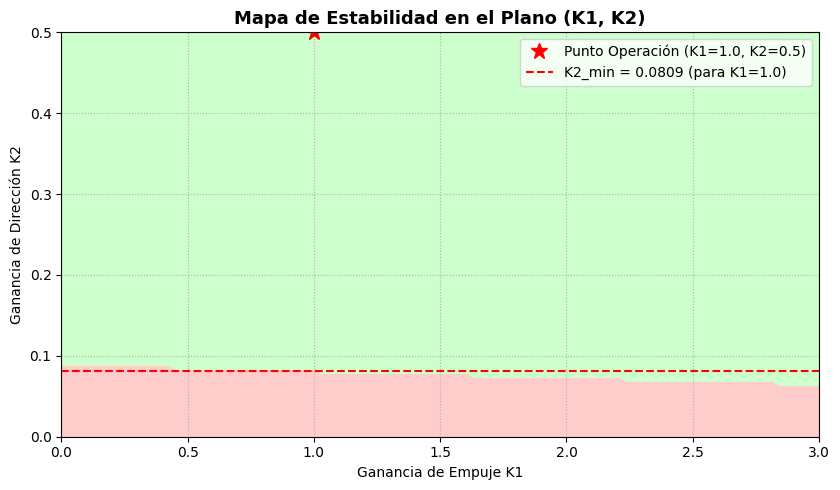

In [7]:
from src.system_rep import numeric_matrixes

k1_grid = np.linspace(0, 3.0, 100)
k2_grid = np.linspace(0, 0.5, 100)
K1_mesh, K2_mesh = np.meshgrid(k1_grid, k2_grid)
stable = np.zeros_like(K1_mesh, dtype=bool)

for i in range(K1_mesh.shape[0]):
    for j in range(K1_mesh.shape[1]):
        A_k, _, _, _ = numeric_matrixes(A, B, C, D, {k1: K1_mesh[i, j], k2: K2_mesh[i, j]})
        poles = np.linalg.eigvals(A_k)
        stable[i, j] = np.all(np.real(poles) < 0)

plt.figure(figsize=(8.5, 5))
plt.contourf(K1_mesh, K2_mesh, stable, levels=[-0.5, 0.5, 1.5], colors=['#ffcccc', '#ccffcc'])
plt.plot(1.0, 0.5, 'r*', markersize=12, label="Punto Operación (K1=1.0, K2=0.5)")
plt.axhline(y=0.0809, color='r', linestyle='--', label="K2_min = 0.0809 (para K1=1.0)")
plt.xlabel("Ganancia de Empuje K1")
plt.ylabel("Ganancia de Dirección K2")
plt.title("Mapa de Estabilidad en el Plano (K1, K2)", fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()

#### 7) Respuesta del sistema

In [8]:
# H(t) - H(t-5)
def step(t):
    return np.where((t >= 0) & (t < 5), 1, 0)
# sin(t)
def sen(t):
    return np.sin(t)
# K * δ(t)  
def pulse(t, K: float = 100):
    return np.where(t == 0, K, 0)
# f(t) = 0
def zeros(t):
    return np.zeros_like(t)

tests = [
    ("Pulso Cuadrado en u1 (u2=0)",     step,  zeros),
    ("Senoidal en u1 (u2=0)",           sen,   zeros),
    ("Impulso Dirac en u1 (u2=0)",      pulse, zeros),
    ("Pulso Cuadrado en u2 (u1=0)",     zeros, step),
    ("Senoidal en u2 (u1=0)",           zeros, sen),
    ("Impulso Dirac en u2 (u1=0)",      zeros, pulse),
    ("Pulso Cuadrado en Ambas (u1=u2)", step,  step),
    ("Senoidal en Ambas (u1=u2)",       sen,   sen),
    ("Impulso Dirac en Ambas (u1=u2)",  pulse, pulse)
]
values = [
    {k1: 2.50, k2: 0.25},
    {k1: 1.50, k2: 0.80},
    {k1: 1.00, k2: 1.00},
    {k1: 0.80, k2: 1.50},
    {k1: 0.25, k2: 2.50}
]

INTERPRETACIÓN FÍSICA DE SEÑALES DE ENTRADA:
- u1(t) = H(t) - H(t-5): Implica una aceleración momentánea de 5s por el motor o algún motor secundario
  (genera un empuje que causa aceleración axial).
- u1(t) = sen(t): El motor da tirones (acelera y se apaga); el término investigado para esto en motores es "efecto chugging".
- u1(t) = K δ_DIRAC(t): Una pequeña aceleración de golpe (un tirón brusco).
- u2(t) = H(t) - H(t-5): Son vientos sostenidos que soplan de manera continua durante un tiempo determinado (5s),
  pudiendo verse como corrientes atmosféricas entre los 6 a 15 km de altura que inclinan el cohete.
- u2(t) = sen(t): Son turbulencias atmosféricas periódicas en fenómenos como remolinos de viento o vortex shedding
  que hacen que el cohete oscile conforme asciende.
- u2(t) = K δ_DIRAC(t): Representa una ráfaga de viento o golpe repentino al cohete que afecta la dirección e influye en la tobera.

Pulso Cuadrado en u1 (u2=0)


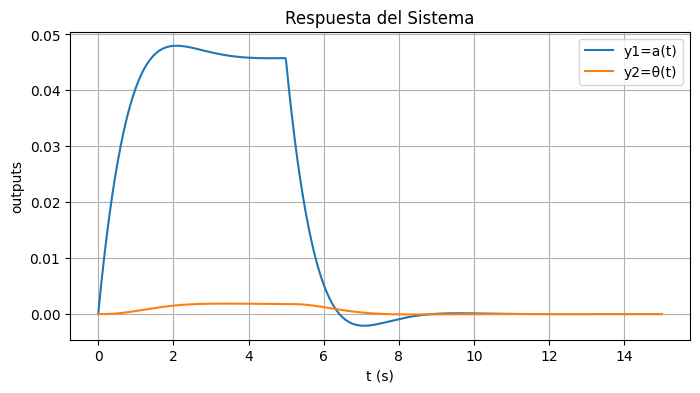

Senoidal en u1 (u2=0)


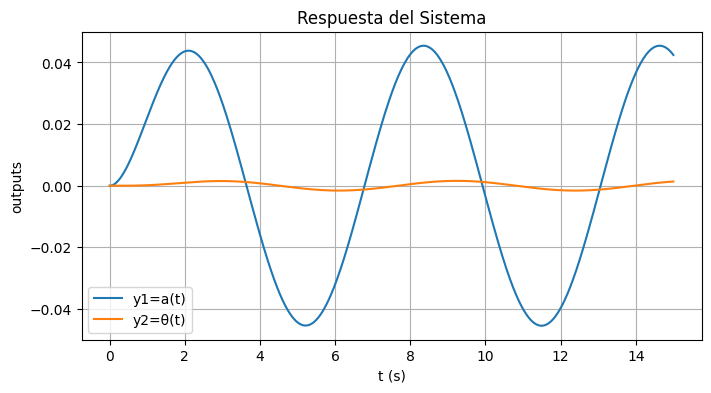

Impulso Dirac en u1 (u2=0)


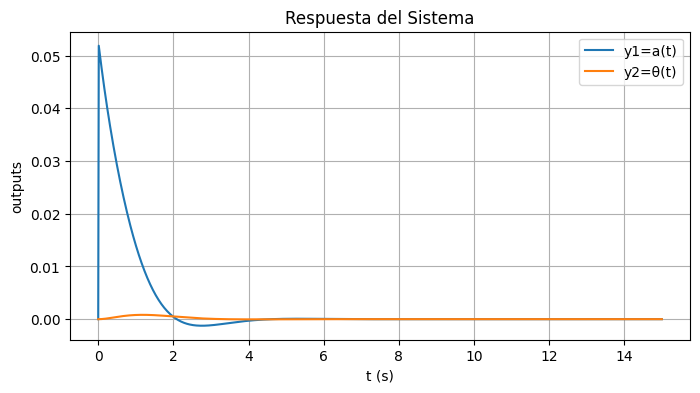

Pulso Cuadrado en u2 (u1=0)


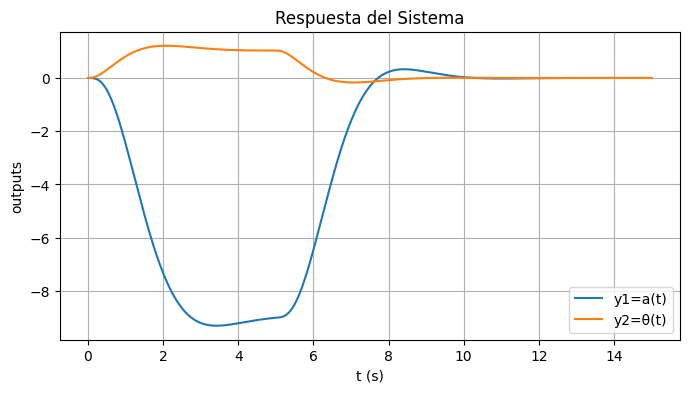

Senoidal en u2 (u1=0)


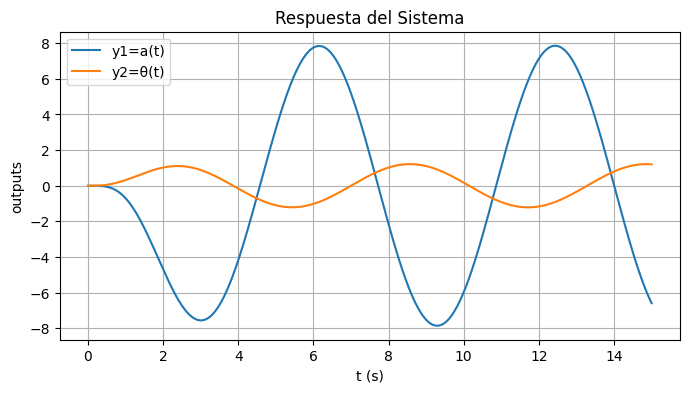

Impulso Dirac en u2 (u1=0)


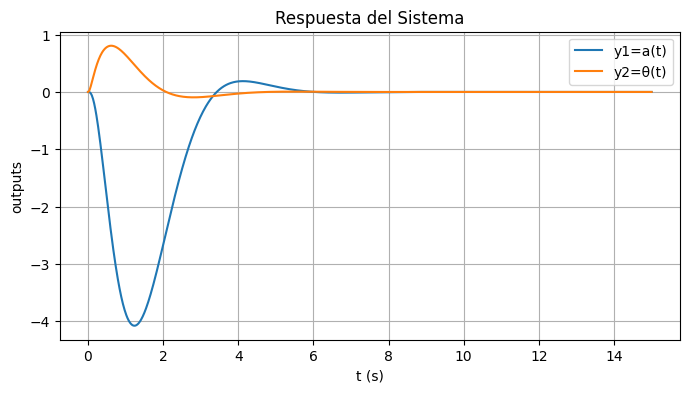

Pulso Cuadrado en Ambas (u1=u2)


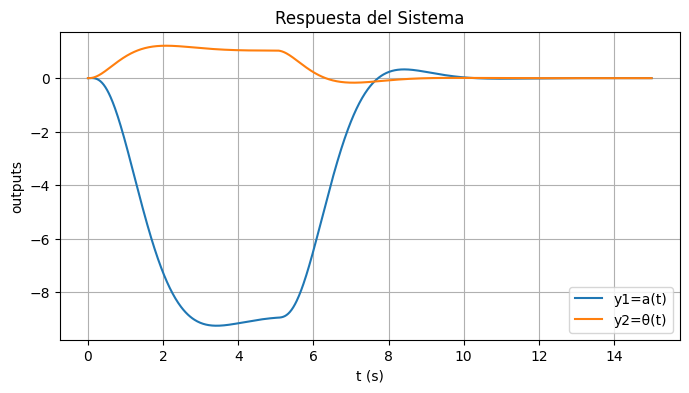

Senoidal en Ambas (u1=u2)


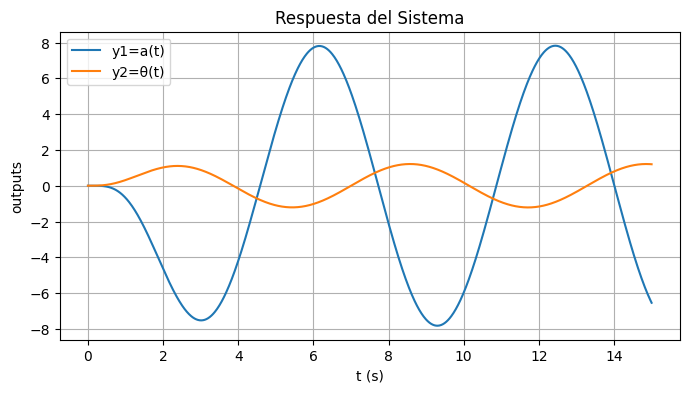

Impulso Dirac en Ambas (u1=u2)


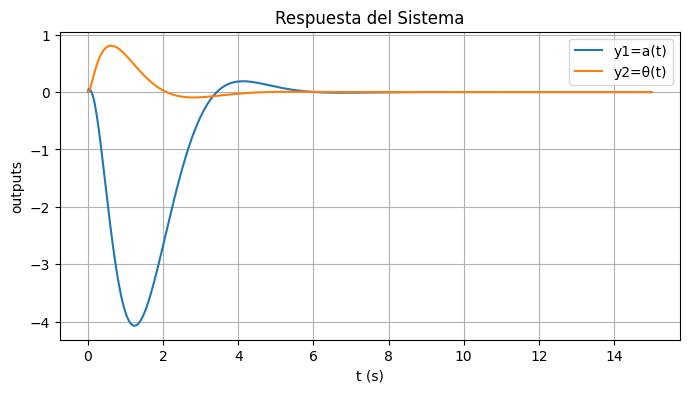

In [9]:
A0, B0, C0, D0 = numeric_matrixes(A, B, C, D, {k1: 1, k2: 0.5})
T = np.linspace(0.0, 15.0, 1000)
ss_sys = signal.StateSpace(A0, B0, C0, D0)

for test in tests:
    U = np.column_stack((test[1](T), test[2](T)))
    t_out, y_out, x_out = signal.lsim(ss_sys, U=U, T=T)

    plt.figure(figsize=(8, 4))
    print(test[0])
    # plt.plot(t_out, tests[0][1](T), label="u1")
    # plt.plot(t_out, tests[0][2](T), label="u2")
    plt.plot(t_out, y_out[:,0], label="y1=a(t)")
    plt.plot(t_out, y_out[:,1], label="y2=θ(t)")
    plt.xlabel("t (s)")
    plt.ylabel("outputs")
    plt.title("Respuesta del Sistema")
    plt.legend()
    plt.grid(True)
    plt.show()

K1: 2.5, K2: 0.25


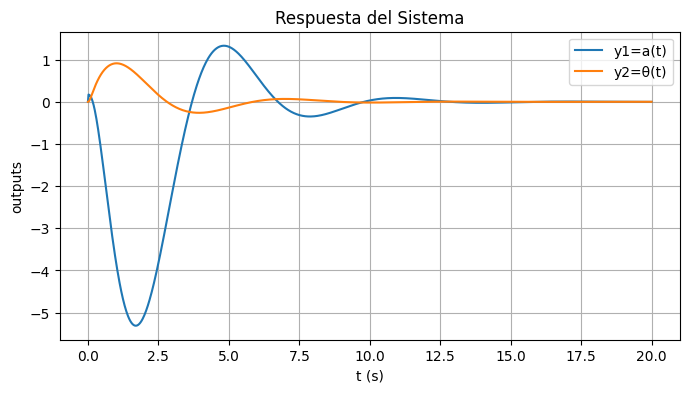

K1: 1.5, K2: 0.8


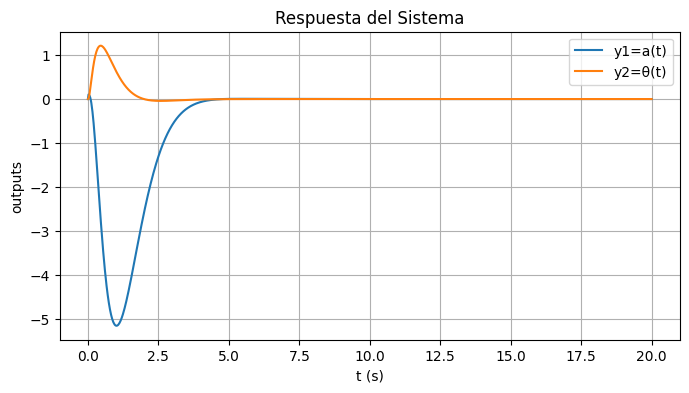

K1: 1.0, K2: 1.0


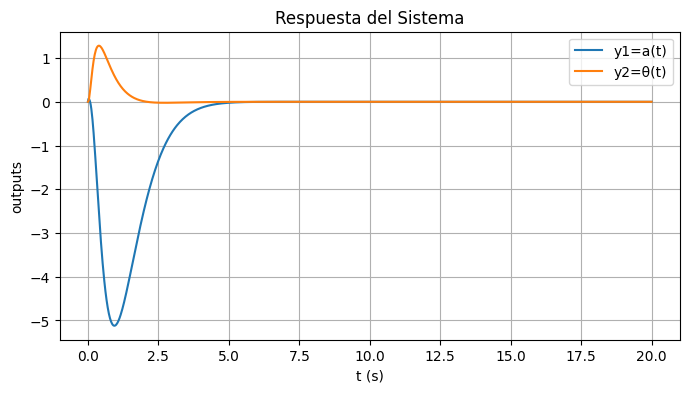

K1: 0.8, K2: 1.5


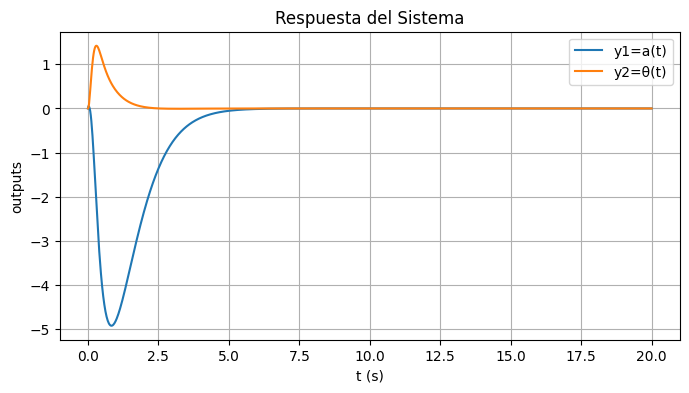

K1: 0.25, K2: 2.5


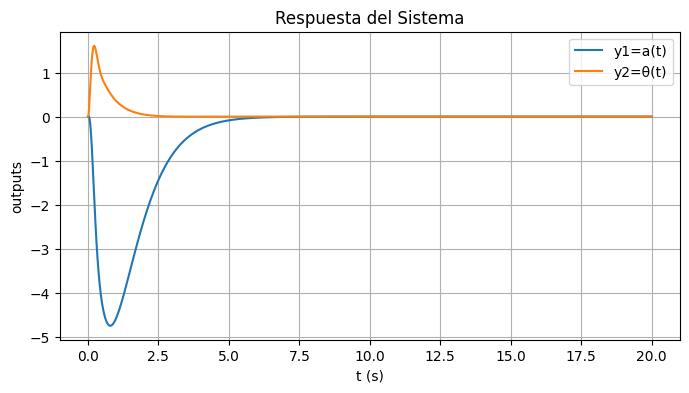

In [10]:
for val in values:
    A0, B0, C0, D0 = numeric_matrixes(A, B, C, D, val)

    T = np.linspace(0.0, 20.0, 1000)
    U = np.column_stack((pulse(T), pulse(T)))

    state_space = signal.StateSpace(A0, B0, C0, D0)
    t_out, y_out, x_out = signal.lsim(state_space, U=U, T=T)

    plt.figure(figsize=(8, 4))
    print(f"K1: {val[k1]}, K2: {val[k2]}")
    plt.plot(t_out, y_out[:,0], label="y1=a(t)")
    plt.plot(t_out, y_out[:,1], label="y2=θ(t)")
    plt.xlabel("t (s)")
    plt.ylabel("outputs")
    plt.title("Respuesta del Sistema")
    plt.legend()
    plt.grid(True)
    plt.show()

CONCLUSIÓN DE VARIACIÓN DE GANANCIAS DE LA TABLA:

Por lo que podemos concluir es que si aumentamos demasiado K1 y no K2 entonces nuestro sistema
perderá estabilidad y tardará mucho en converger a un valor; al contrario, si aumentamos demasiado
K2 con respecto a K1 el sistema se sobreamortiguará lo que lo seguirá manteniendo estable pero poco
a poco también aumenta el tiempo para converger a un valor. Sin embargo, al mantener valores cercanos
entre ellos de K1 y K2 el sistema es bastante estable y el tiempo de asentamiento no aumenta demasiado,
siendo el más rápido cuando K1 es algo mayor a K2.

### 8) Cuantificación de Acoplamiento

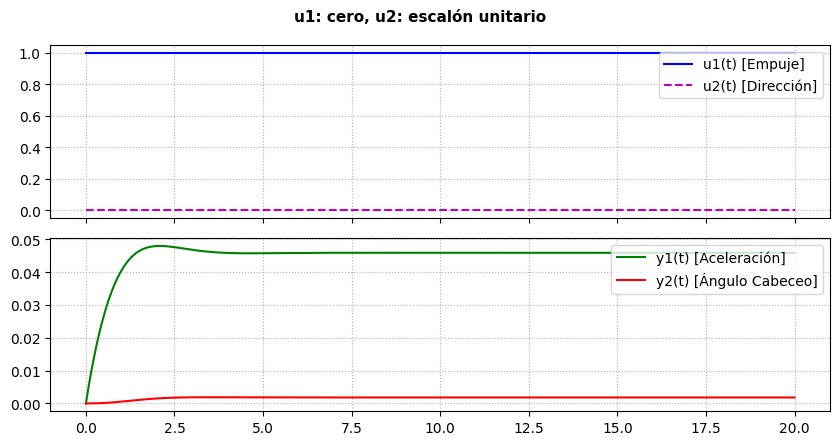

In [16]:
u_step = np.ones_like(T)
u_zeros = np.zeros_like(T)
U1 = np.column_stack((u_step, u_zeros))
t_out, y_out, _ = signal.lsim(ss_sys, U=U1, T=T)

fig, axs = plt.subplots(2, 1, figsize=(8.5, 4.5), sharex=True)
axs[0].plot(t_out, u_step, 'b-', label='u1(t) [Empuje]')
axs[0].plot(t_out, u_zeros, 'm--', label='u2(t) [Dirección]')
axs[0].legend(loc='upper right')
axs[0].grid(True, linestyle=':')
axs[1].plot(t_out, y_out[:, 0], 'g-', label='y1(t) [Aceleración]')
axs[1].plot(t_out, y_out[:, 1], 'r-', label='y2(t) [Ángulo Cabeceo]')
axs[1].legend(loc='upper right')
axs[1].grid(True, linestyle=':')
plt.suptitle("u1: cero, u2: escalón unitario", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()
plt.close('all')

Como u2 es cero, únicamente tomamos en cuenta las funciones de transferencia G11(s) y G21(s).
Aplicando el teorema de valor final (Evaluamos en cero las funciones de transferencia):
  $$a(t) = 4.264 / 92.9072 = 0.0459 m/s²$$
  $$θ(t) = 0.1678 / 92.9072 = 0.001806 rad = 0.1035°$$

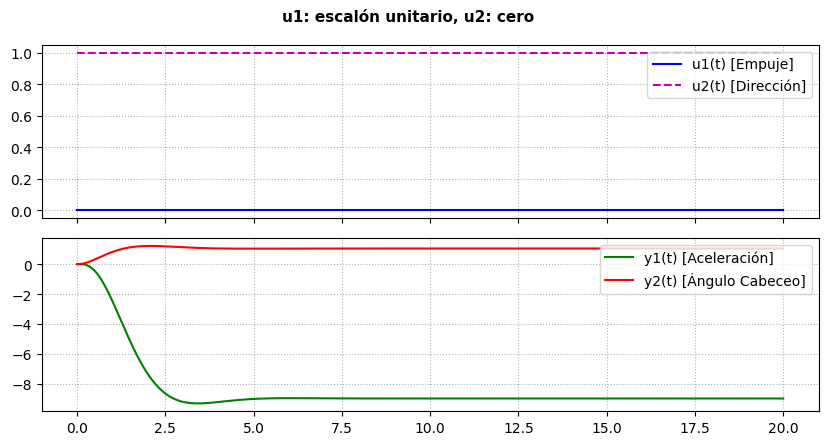

In [17]:
U2 = np.column_stack((u_zeros, u_step))
t_out, y_out, _ = signal.lsim(ss_sys, U=U2, T=T)

fig, axs = plt.subplots(2, 1, figsize=(8.5, 4.5), sharex=True)
axs[0].plot(t_out, u_zeros, 'b-', label='u1(t) [Empuje]')
axs[0].plot(t_out, u_step, 'm--', label='u2(t) [Dirección]')
axs[0].legend(loc='upper right')
axs[0].grid(True, linestyle=':')
axs[1].plot(t_out, y_out[:, 0], 'g-', label='y1(t) [Aceleración]')
axs[1].plot(t_out, y_out[:, 1], 'r-', label='y2(t) [Ángulo Cabeceo]')
axs[1].legend(loc='upper right')
axs[1].grid(True, linestyle=':')
plt.suptitle("u1: escalón unitario, u2: cero", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()
plt.close('all')

Como u1 es cero, únicamente tomamos en cuenta las funciones de transferencia G12(s) y G22(s).
Aplicando el teorema de valor final (Evaluamos en cero las funciones de transferencia):
  $$a(t) = -833.85 / 92.9072 = -8.9751 m/s²$$
  $$θ(t) = 96.6536 / 92.9072 = 1.0403 rad = 59.6062°$$

[CONCLUSIÓN FINAL DE ACOPLAMIENTO]:

El acoplamiento más severo es el de nuestra entrada u2(t) ya que influye en la aceleración
negativamente con un valor de -8.9751 m/s² algo que afecta significativamente a la aceleración
del cohete provocando un lastre mientras se eleva, en cambio la entrada u1(t) no influye tan
significativamente aumentando el valor de nuestro ángulo de cabeceo del cohete en
0.001806 rad = 0.1035° algo que es insignificante a comparación de la influencia en la
aceleración de nuestra entrada u2(t).

## (C) Respuesta en frecuencia

### 9) Respuesta en Frecuencia

In [ ]:
from src.system_rep import numeric_matrixes

A0, B0, C0, D0 = numeric_matrixes(A, B, C, D, {k1: 1, k2: 0})
matA = sp.Matrix(A0)
matB = sp.Matrix(B0)
matC = sp.Matrix(C0)
matD = sp.Matrix(D0)

w = np.logspace(-2, 3, 1000)
fig, axs = plt.subplots(2, 2, figsize=(10, 6.5))
titulos0 = [
    ["G11(s): U1 -> Y1 (Empuje a Aceleración)", "G12(s): U2 -> Y1 (Dirección a Aceleración)"],
    ["G21(s): U1 -> Y2 (Empuje a Cabeceo)", "G22(s): U2 -> Y2 (Dirección a Cabeceo)"]
]

for i in range(2):
    for j in range(2):
        sys_ij = signal.StateSpace(matA, matB[:,j], matC[i,:], matD[i,j])
        _, mag, phase = signal.bode(sys_ij, w)
        ax1 = axs[i, j]
        ax2 = ax1.twinx()
        ax1.semilogx(w, mag, 'b')
        ax2.semilogx(w, phase, 'r')
        ax1.set_title(titulos0[i][j], fontsize=9, fontweight='bold')
        ax1.grid(True, which="both", linestyle=':', alpha=0.6)

plt.suptitle("Matriz de Diagramas de Bode 2x2 (K1 = 1.0, K2 = 0.0) [SISTEMA INESTABLE]", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 10) Ancho de Banda y Pico de Resonancia

## (D) Observabilidad y Controlabilidad

### 11) Observabilidad

### 12) Controlabilidad

## (E) Seleccion de ganancias y muestreo